# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and skewness for k-means clustering and thresholding.

In [246]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [247]:

%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [248]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1]  # amplitude of each sine wave
frequencies = [5, 13]  # frequency content of signal
phases = [0, np.deg2rad(45)]  # phase of each sine wave

duration = 300 / min(frequencies)  # duration of wave

trans_amp = [2 for _ in range(3)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

/tmp/ipykernel_62276/1457866422.py:25: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


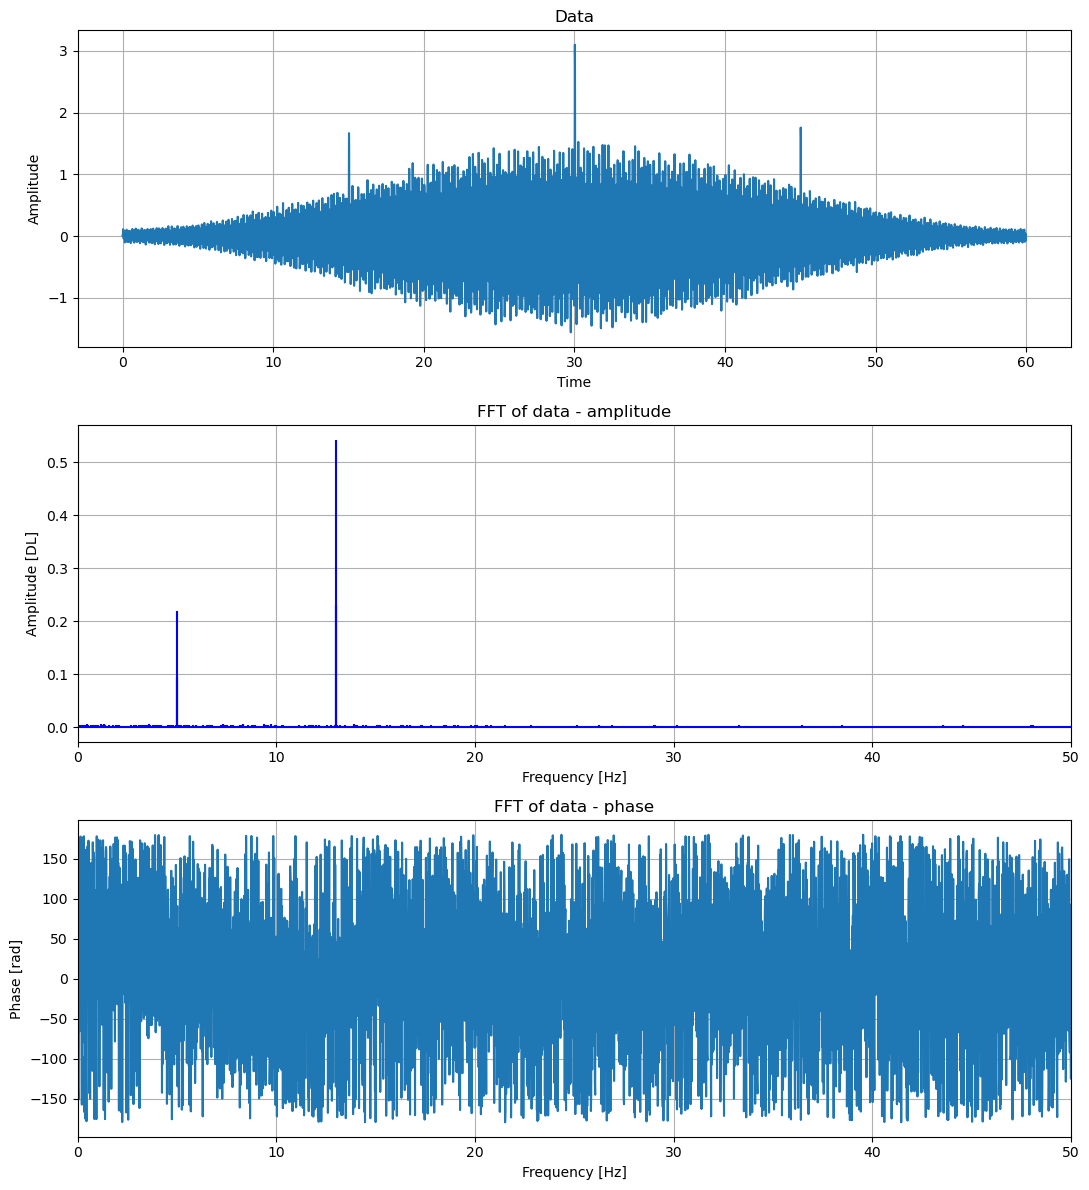

In [249]:
# generate sound wave

data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(
    trans_amp, trans_time, trans_dur, duration, sampling_rate
)
data += transient_signal
data += sd.noise(std_noise, duration, sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

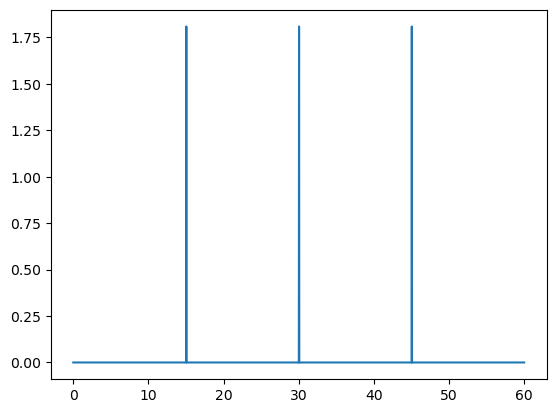

In [250]:
plt.plot(t_plot, transient_signal)
plt.show()

Wavelet transform

In [251]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.calc_energy(data)

# calculate energy, kurtosis, and crest factor of reconstructed signals
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    inverse = inv.inv_dwpt(tr_ob, nodes=node)
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(node_data)
    skewness = stats.calc_skewness(node_data)
    crest = stats.calc_crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = entropy_node
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

In [252]:
wpt_df.head()

,node,inverse,fft,energy,kurtosis,crest,entropy,skewness
0,<wavelet_transform.wpt.transform_object.Node o...,"[0.021521723161795032, 0.02168642236056339, 0....","[(0.0022607770695891845+0j), (-0.0008486380793...",0.010826,18.071011,5.375894,0.201697,2.208965
1,<wavelet_transform.wpt.transform_object.Node o...,"[0.015490699414816117, 0.01584903867212446, 0....","[(1.3470812760235753e-05+0j), (1.3470290528090...",0.006547,9.420222,3.143745,0.141778,-1.018259
2,<wavelet_transform.wpt.transform_object.Node o...,"[0.014760489452976743, 0.011211411586558062, 0...","[(-6.119678134266393e-06+0j), (-6.119954716696...",0.026961,4.320757,-0.206183,0.354385,0.468602
3,<wavelet_transform.wpt.transform_object.Node o...,"[-0.009610362591326903, -0.009583531128288228,...","[(-2.5420421717587142e-05+0j), (-2.54206157608...",0.854055,3.280685,-3.431801,-6.520801,0.017518
4,<wavelet_transform.wpt.transform_object.Node o...,"[0.0017435630699534788, 0.0037377665671438046,...","[(8.781449094313618e-06+0j), (8.78148580148291...",0.028402,4.140153,-0.81908,0.36444,0.426401


<Axes: xlabel='entropy', ylabel='crest'>

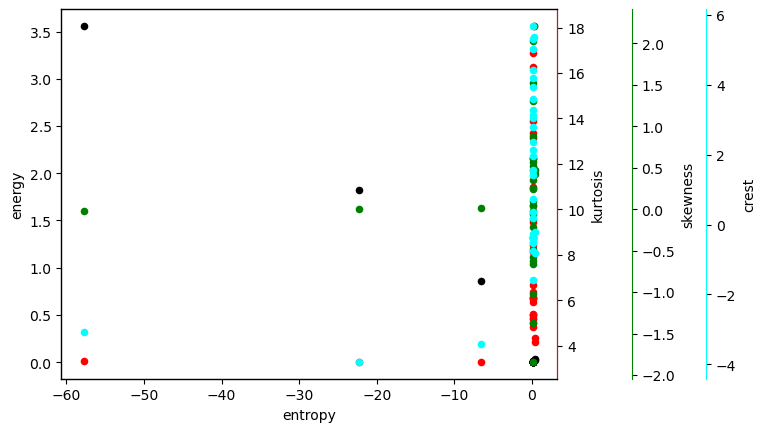

In [253]:
ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.15))
ax_df2.spines['right'].set_edgecolor('green')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.3))
ax_df2.spines['right'].set_edgecolor('cyan')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest',c='cyan')

<Axes: xlabel='kurtosis', ylabel='crest'>

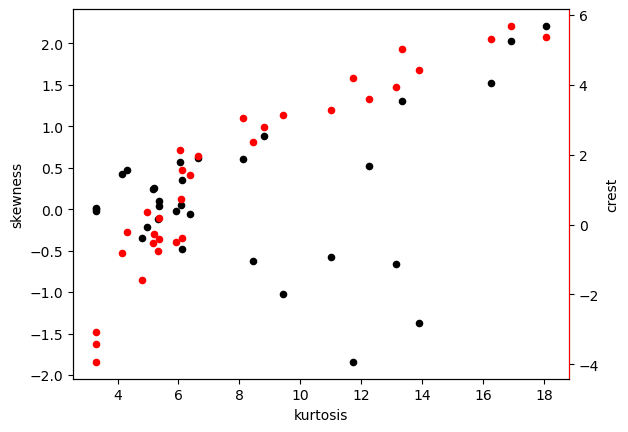

In [254]:
ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

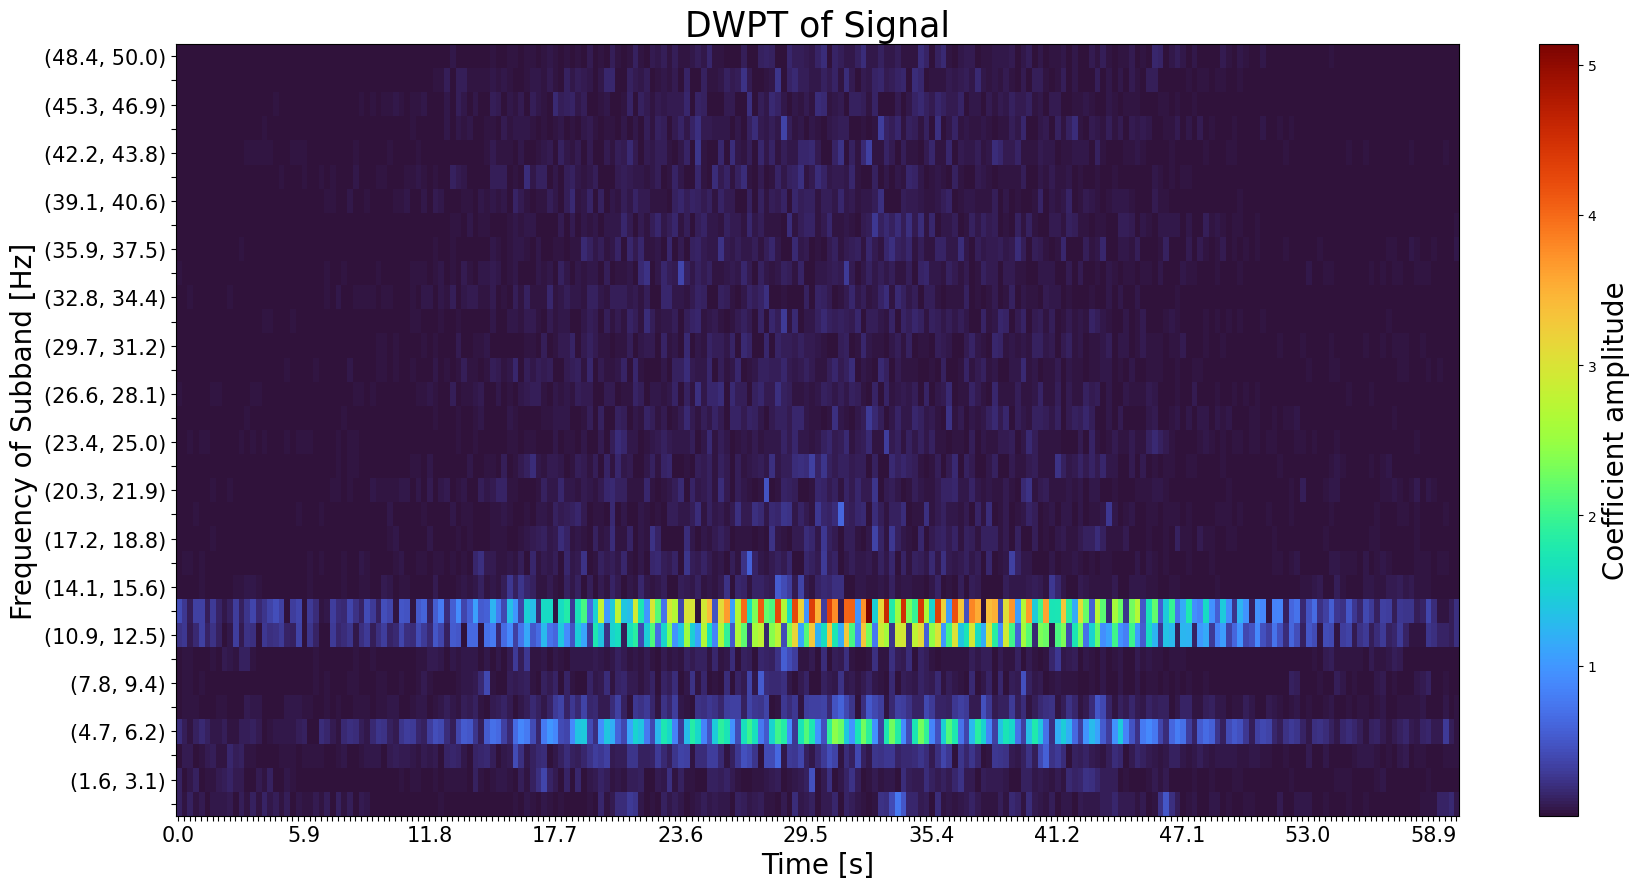

In [255]:
plot.heisenberg(tr_ob, max(t_plot))

<Axes: >

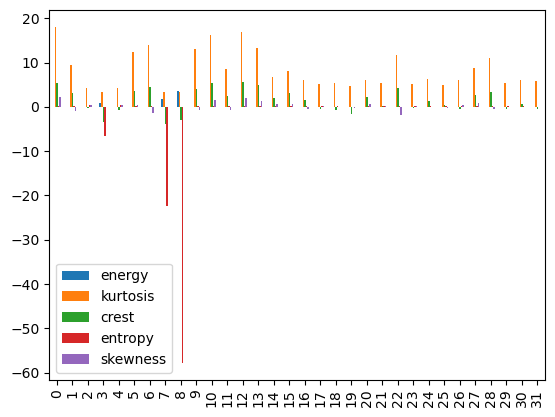

In [256]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [257]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [258]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = ["entropy", "kurtosis", "crest"]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

kmeans = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[ 0.22222892 -0.54405848 -0.38971552]
 [-3.49942954 -1.15304703 -1.88067601]
 [ 0.25542806  1.31872637  1.15556624]]
4


In [259]:
data_train_predict

array([2, 2, 0, 0, 0, 2, 2, 1, 1, 2, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 0, 0, 0, 0, 0, 2, 0, 0, 0], dtype=int32)

In [260]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [20  2 10]
cluster IDs: [0 1 2]


In [261]:
fit_and_evaluate(kmeans, data_train_normalised,name='wpt data')

clustering done in 0.02 ± 0.00 s 
Homogeneity: 1.000 ± 0.000
Completeness: 1.000 ± 0.000
V-measure: 1.000 ± 0.000
Adjusted Rand-Index: 1.000 ± 0.000
Silhouette Coefficient: 0.577 ± 0.000


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [262]:
def assign_labels_entropy(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    lowest entropy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by entropy, lowest entropy is highest group number
    sort_by_entropy = np.argsort(centers[:, 0])[::-1]  # assumes entropy is in 1st position

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete lowest entropy group form kurtosis
        np.where(sort_rest == sort_by_entropy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_entropy, sort_rest)):
        if new_label == len(sort_by_entropy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [263]:
reassigned_labels = assign_labels_entropy(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

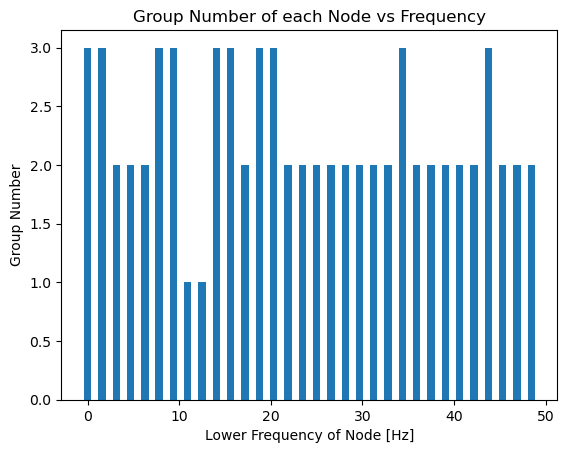

In [264]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_labels)
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [265]:
# apply PCA to training data
pca = PCA(n_components=3)#data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)
reassigned_pca_labels = assign_labels_entropy(centers_pca, labels_pca)

In [266]:
kmeans_pca.cluster_centers_

array([[ 0.50321332, -0.49188437, -0.04571244],
       [-1.69192018,  0.52076929,  0.0762988 ],
       [ 3.42746767,  2.31499725,  0.07563041]])

<Axes: xlabel='principal component 1', ylabel='principal component 3'>

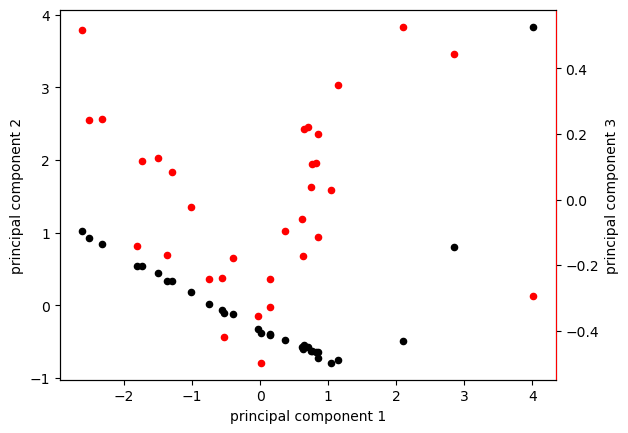

In [267]:
PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
             , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

ax_pca_df2 = ax_pca_df1.twinx()
ax_pca_df2.spines['right'].set_position(('axes', 1.0))
ax_pca_df2.spines['right'].set_edgecolor('red')
PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

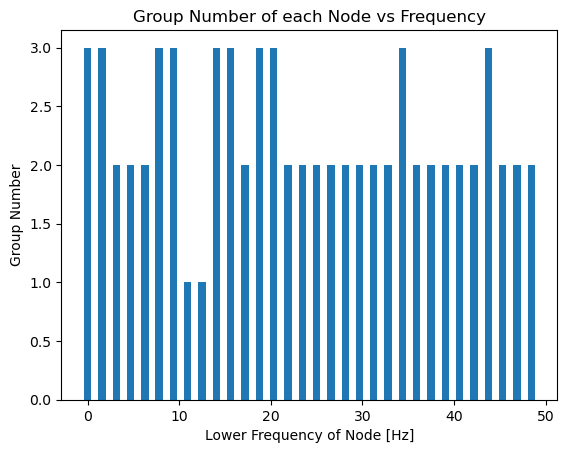

Eigenvectors:
energy, kurtosis, skewness
[[-0.42 -0.62 -0.66]
 [-0.9   0.4   0.19]
 [ 0.15  0.67 -0.73]]
Eigenvalues: [2.23 0.8  0.07]


In [268]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node in wpt_df["node"]]
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_pca_labels)
plt.tick_params
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print("energy, kurtosis, skewness")
print(np.round(eigenvectors, 2))

print("Eigenvalues:", np.round(eigenvalues, 2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

/tmp/ipykernel_62276/1246650002.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("Set1")


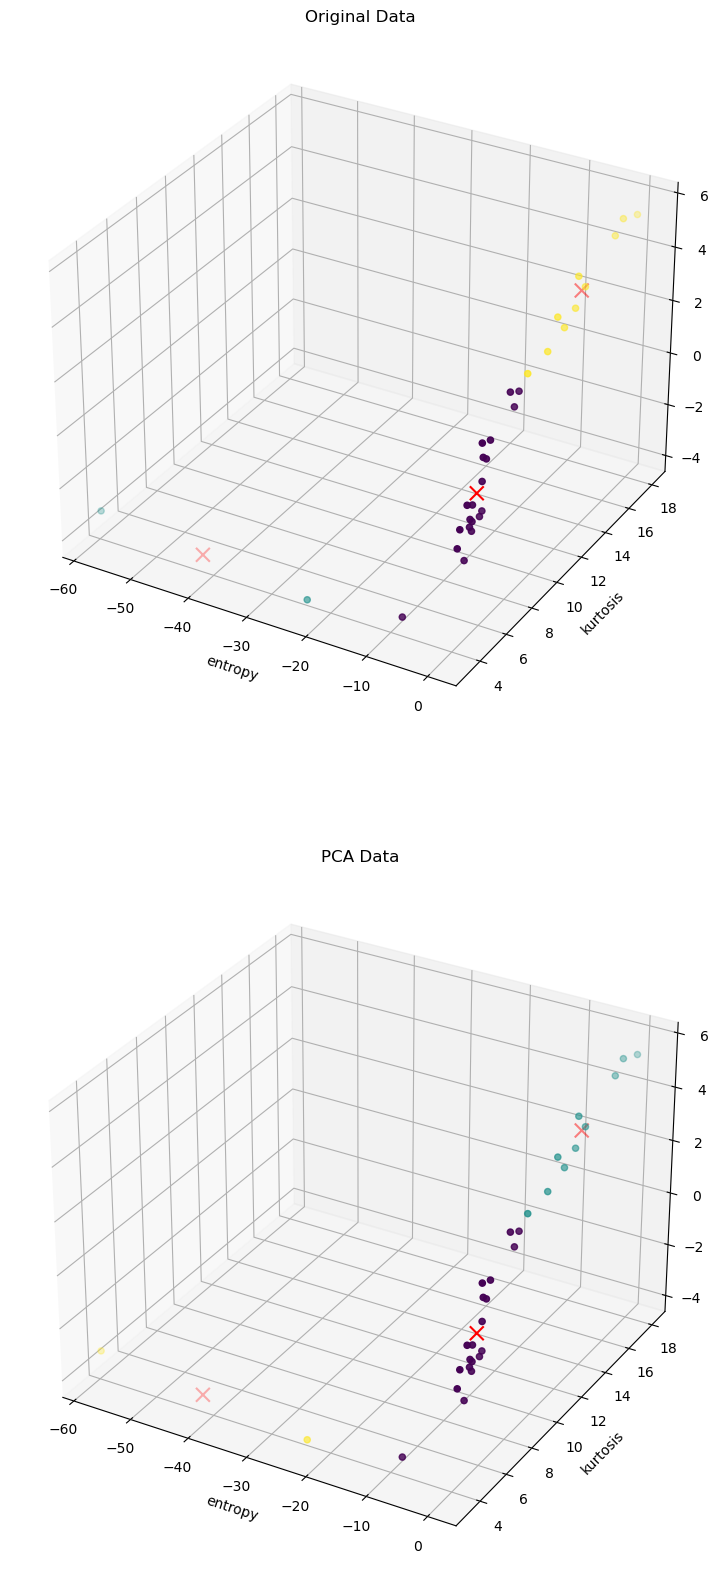

In [269]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = reassigned_labels
        color_map_labels = data_train_predict 
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = data_train_predict_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [270]:
def plot_reconstructions(wpt_recon_df, group=None):
    for i in range(wpt_recon_df.shape[0]):  # highest energy, kurtosis, etc.
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = wpt_recon_df["node"].values.tolist()[i].frequency_range
        ax[0].plot(
            t_plot,
            wpt_recon_df["inverse"].values.tolist()[i],
        )
        title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(wpt_recon_df["fft"].values.tolist()[i]),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed sub-band")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()
        print(wpt_recon_df.iloc[i, 3:])

Change to group=reassign_pca_labels to display the groups assigned using PCA

In [271]:
# plot_reconstructions(wpt_df, group=reassigned_labels)
# plot_reconstructions(wpt_recon_df, group=reassigned_pca_labels)

In [272]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["entropy"] < -1*THR_Factor * np.max(data_train["entropy"])
]
harmonics_data = harmonics_data.sort_values(by="entropy", ascending=False)

In [273]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest"] > THR_Factor * np.max(data_train["crest"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

/tmp/ipykernel_62276/4000348810.py:17: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


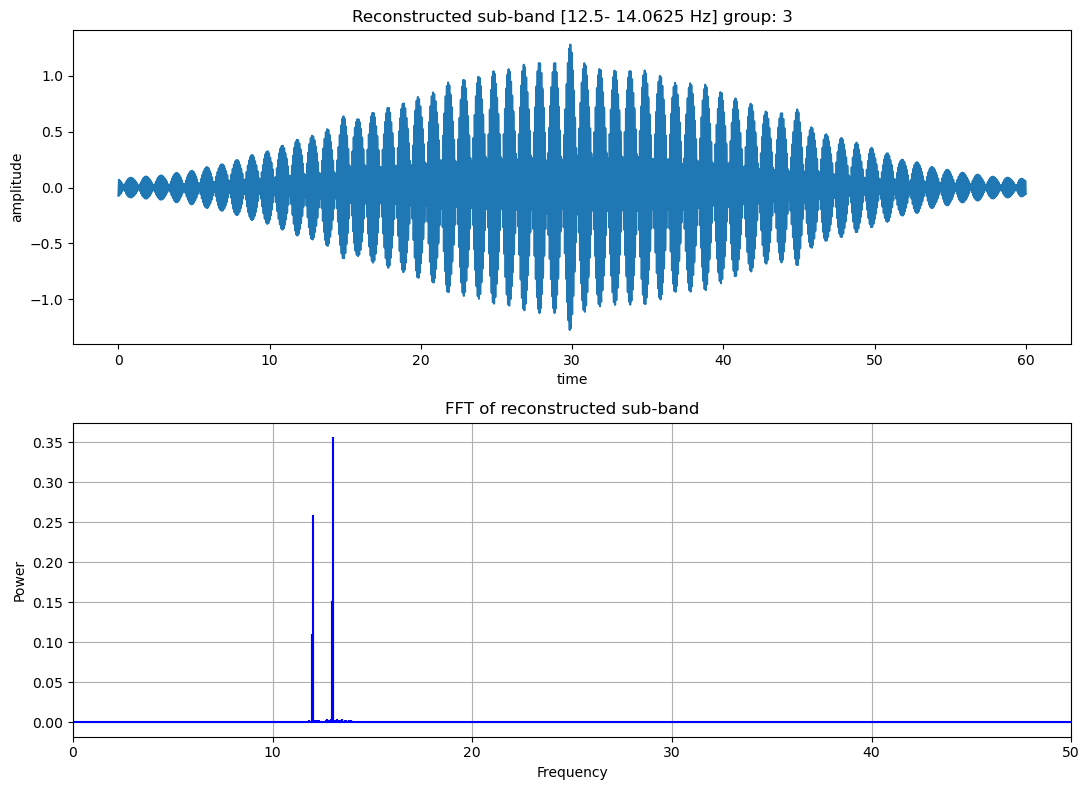

energy       3.559301
kurtosis     3.301058
crest       -3.061621
entropy    -57.724918
skewness    -0.027579
Name: 8, dtype: object


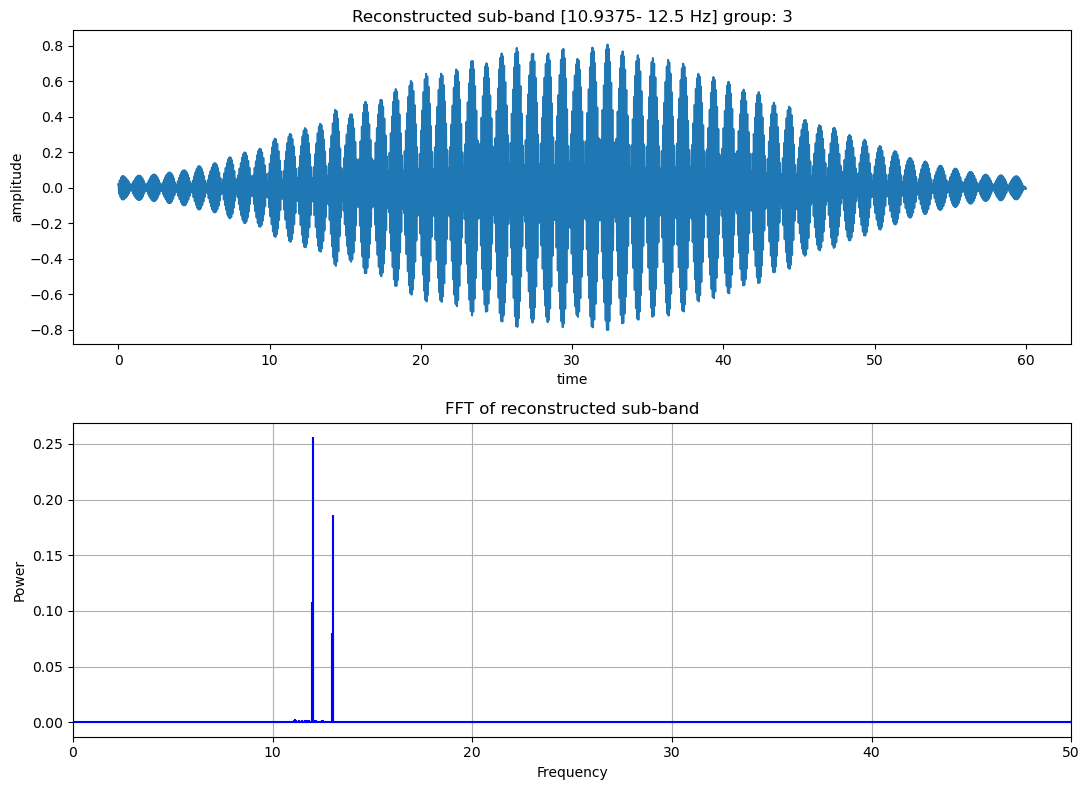

energy        1.82521
kurtosis     3.280821
crest       -3.931708
entropy    -22.271101
skewness     0.004236
Name: 7, dtype: object


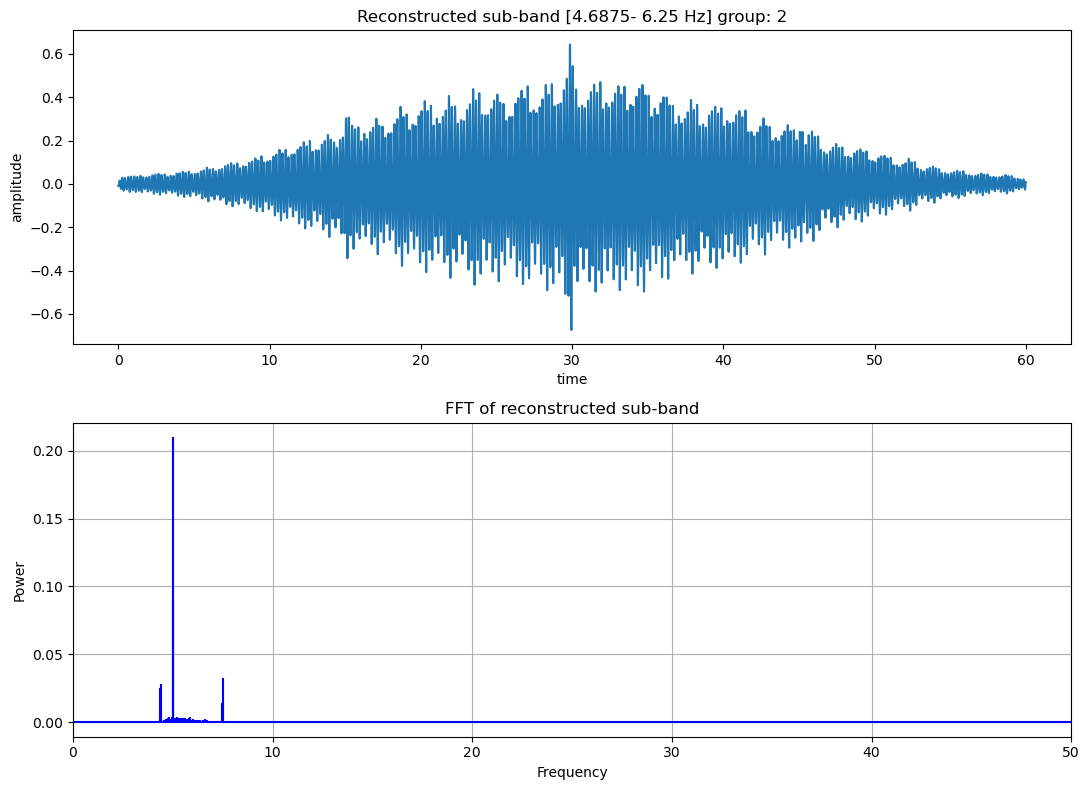

energy      0.854055
kurtosis    3.280685
crest      -3.431801
entropy    -6.520801
skewness    0.017518
Name: 3, dtype: object


In [274]:
plot_reconstructions(harmonics_data, group=reassigned_labels)

/tmp/ipykernel_62276/4000348810.py:17: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


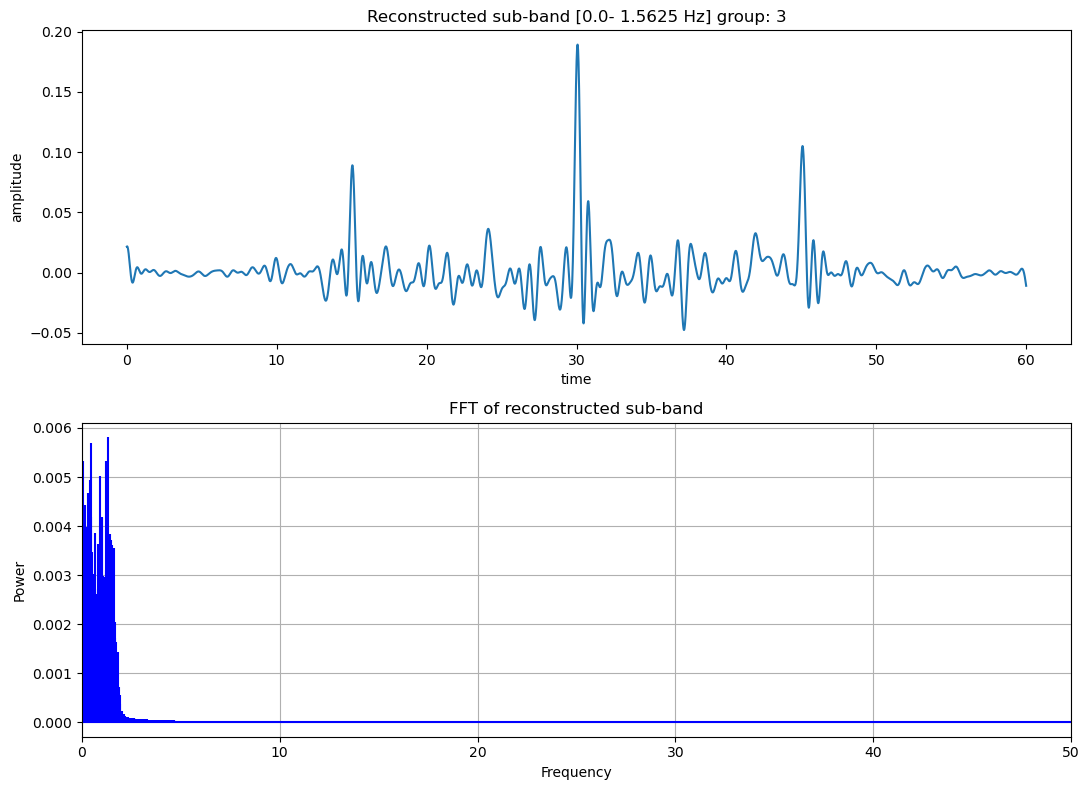

energy       0.010826
kurtosis    18.071011
crest        5.375894
entropy      0.201697
skewness     2.208965
Name: 0, dtype: object


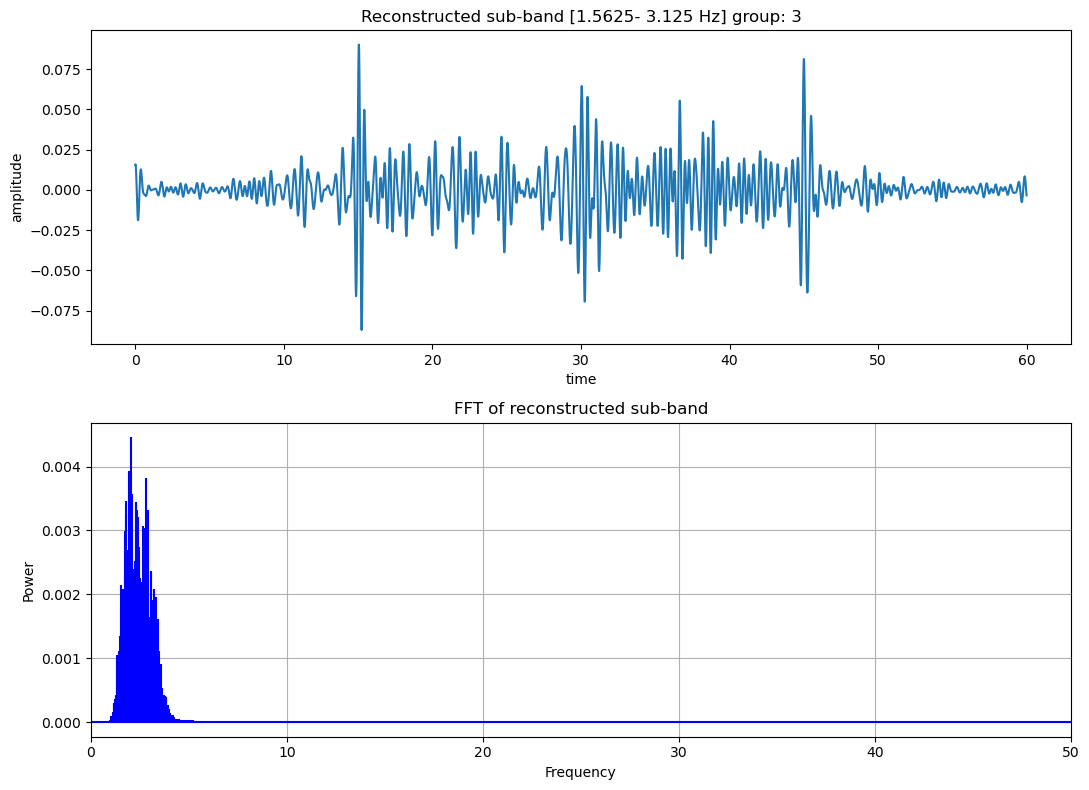

energy      0.006547
kurtosis    9.420222
crest       3.143745
entropy     0.141778
skewness   -1.018259
Name: 1, dtype: object


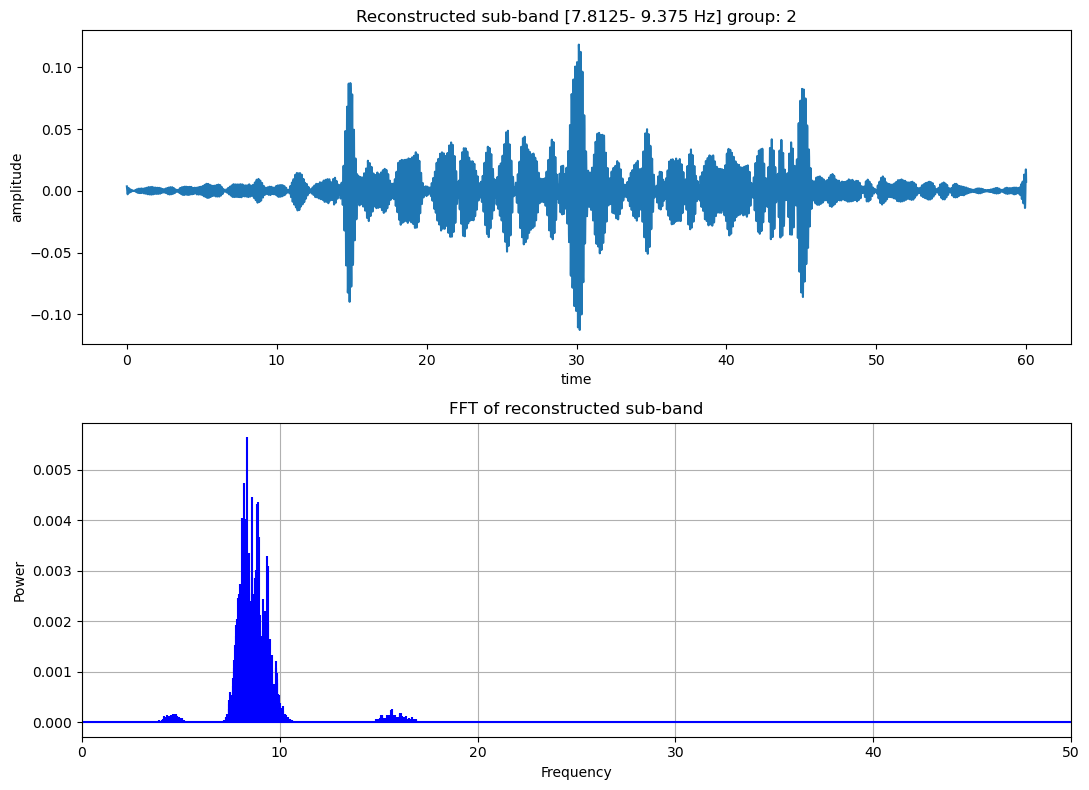

energy       0.008032
kurtosis    12.260941
crest        3.601174
entropy      0.164071
skewness     0.524384
Name: 5, dtype: object


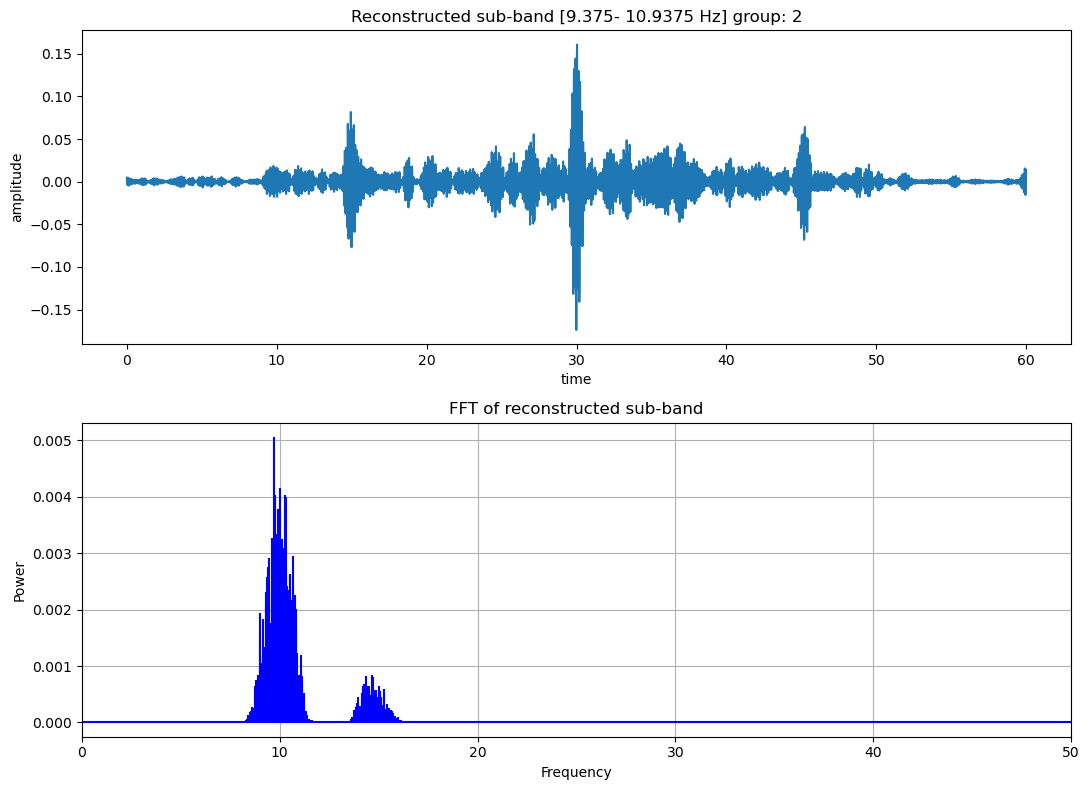

energy       0.007135
kurtosis    13.892381
crest        4.411743
entropy      0.150826
skewness     -1.37316
Name: 6, dtype: object


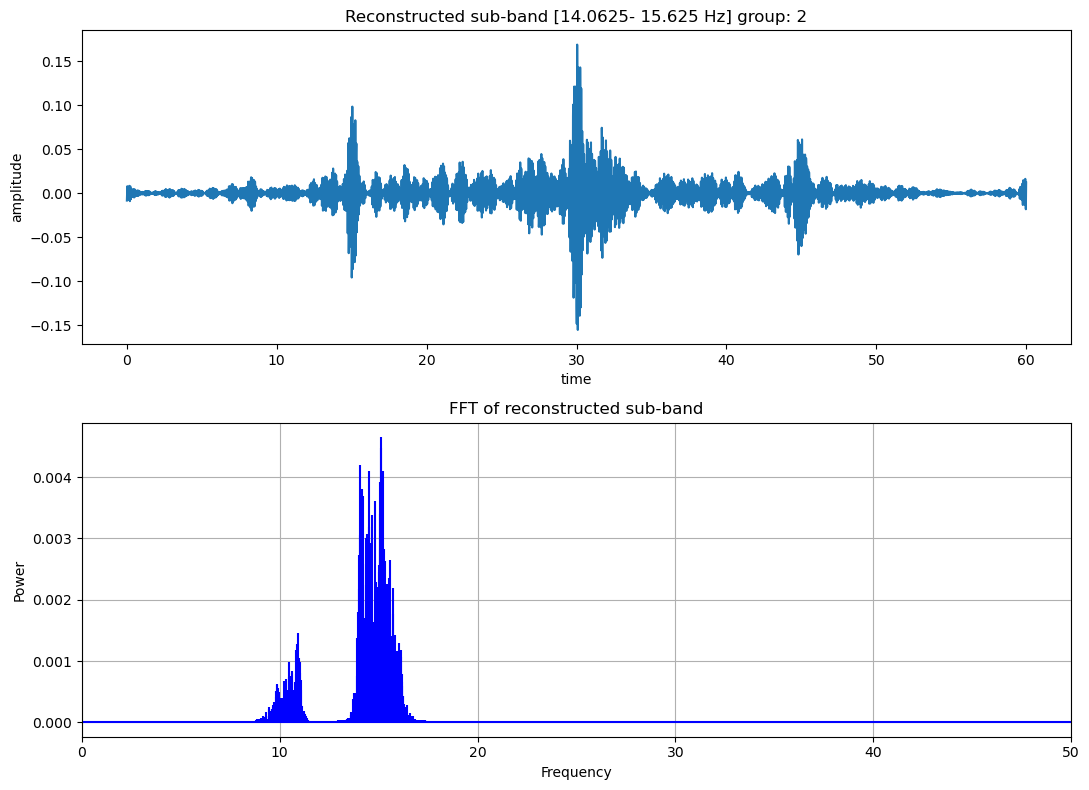

energy       0.007328
kurtosis    13.129521
crest        3.944641
entropy      0.153733
skewness     -0.65776
Name: 9, dtype: object


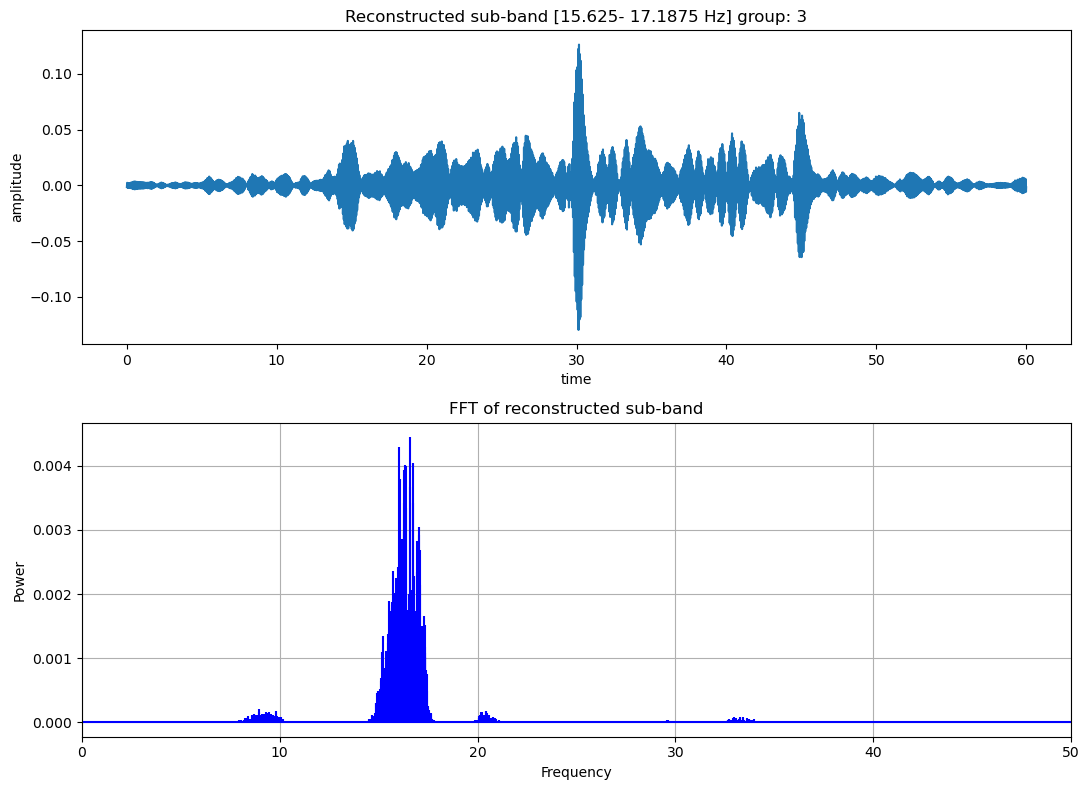

energy       0.006612
kurtosis    16.262749
crest        5.311367
entropy      0.142801
skewness     1.520417
Name: 10, dtype: object


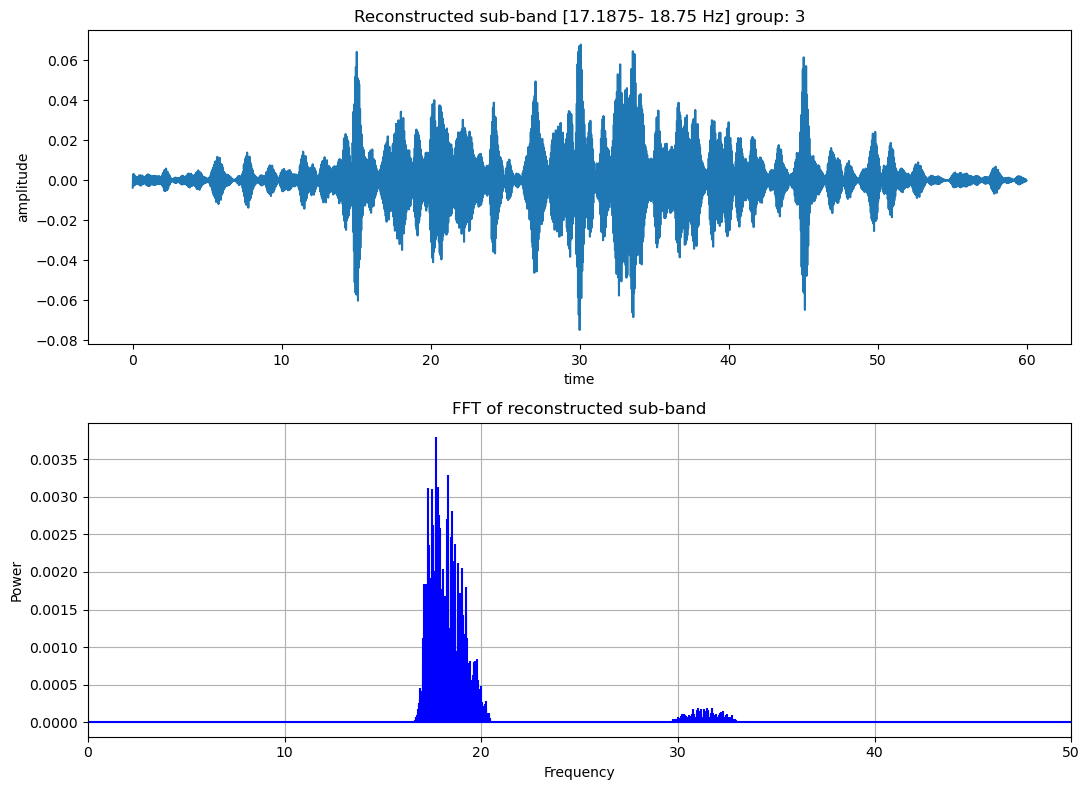

energy       0.00475
kurtosis    8.447017
crest       2.363473
entropy      0.11203
skewness   -0.622334
Name: 11, dtype: object


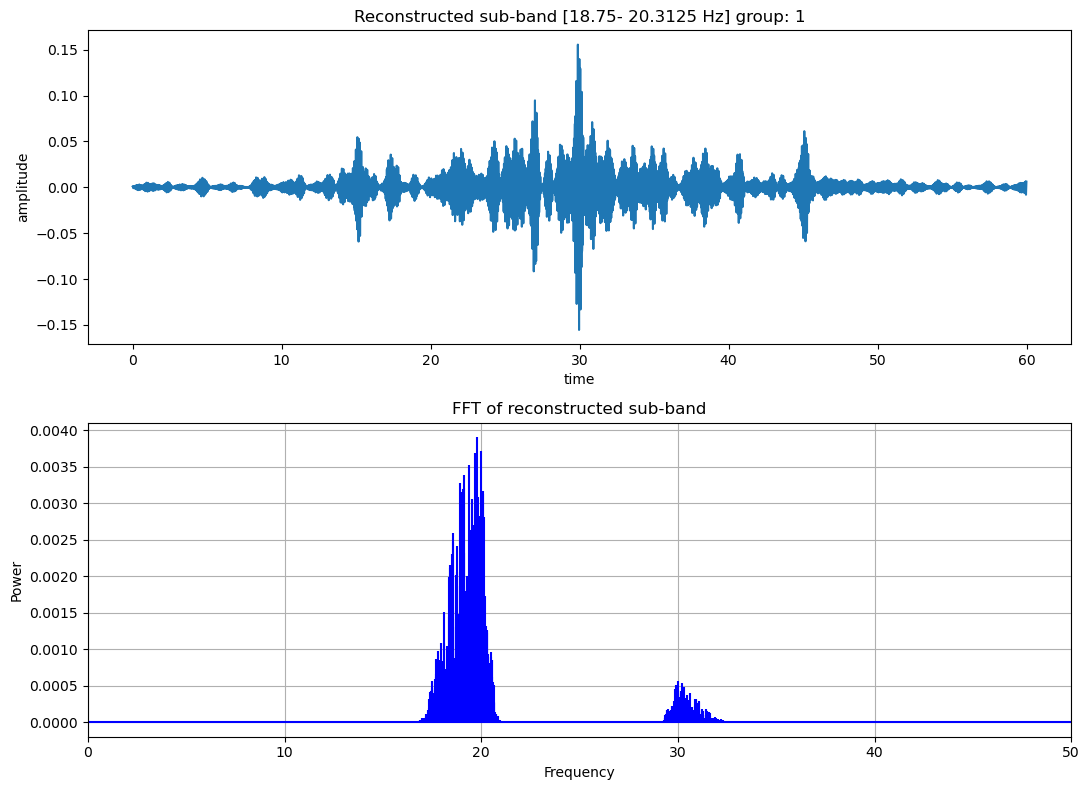

energy       0.006618
kurtosis    16.899949
crest         5.68346
entropy      0.142894
skewness     2.022869
Name: 12, dtype: object


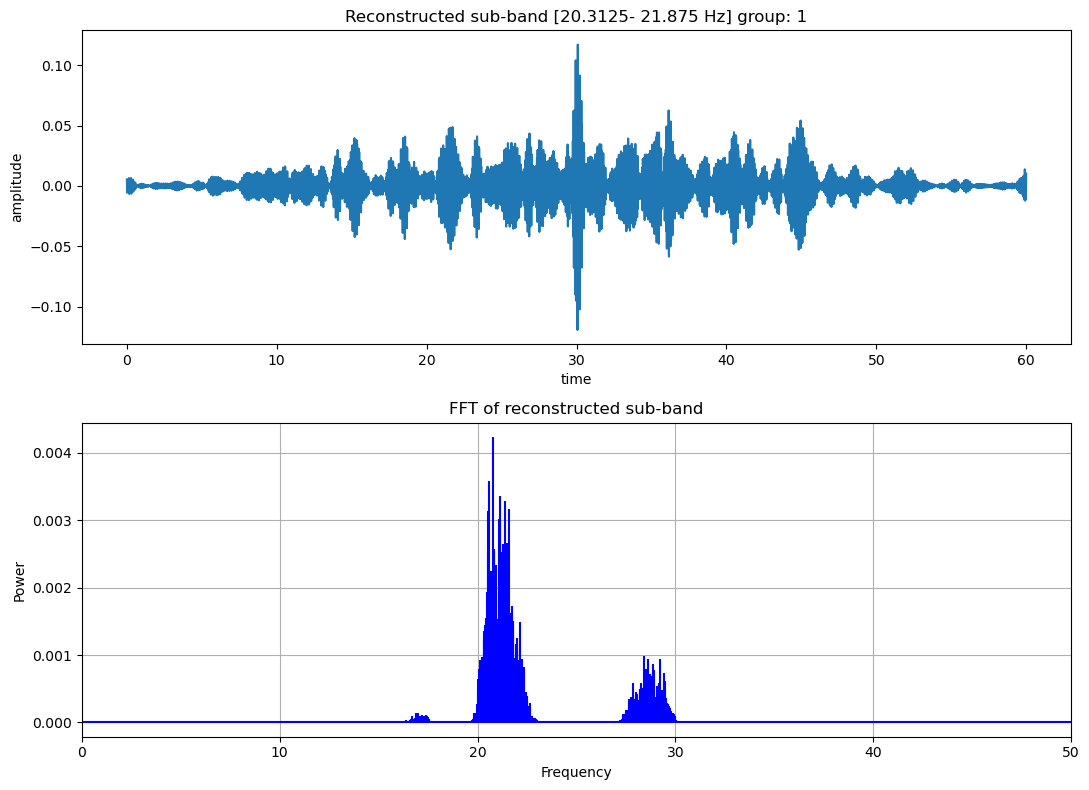

energy       0.004846
kurtosis    13.337129
crest        5.018761
entropy      0.113702
skewness     1.308071
Name: 13, dtype: object


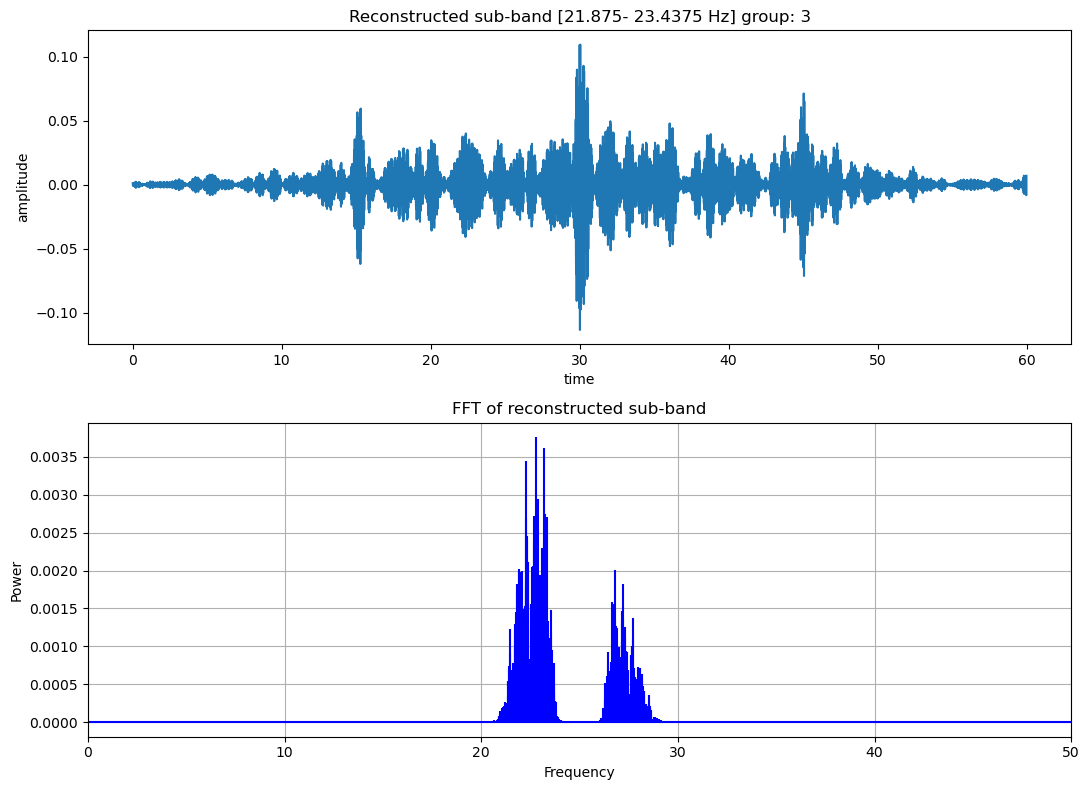

energy      0.004843
kurtosis    6.645684
crest        1.96363
entropy     0.113663
skewness    0.613479
Name: 14, dtype: object


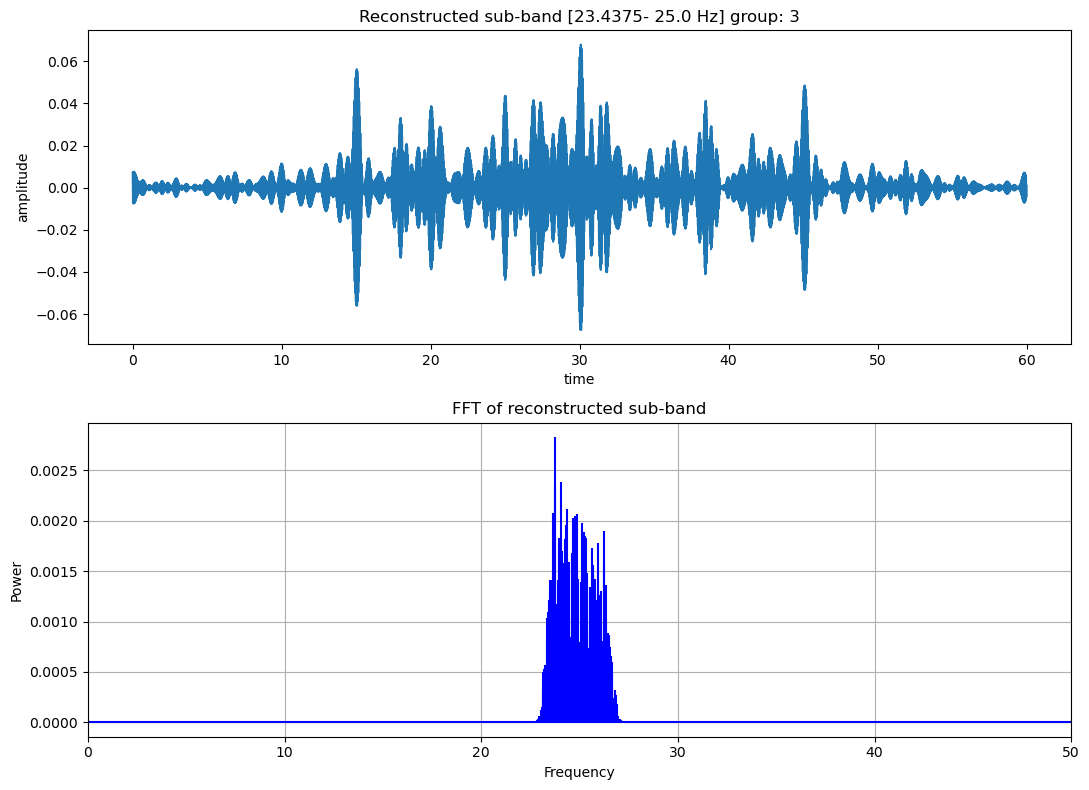

energy      0.003239
kurtosis    8.122537
crest       3.038282
entropy     0.083853
skewness    0.608306
Name: 15, dtype: object


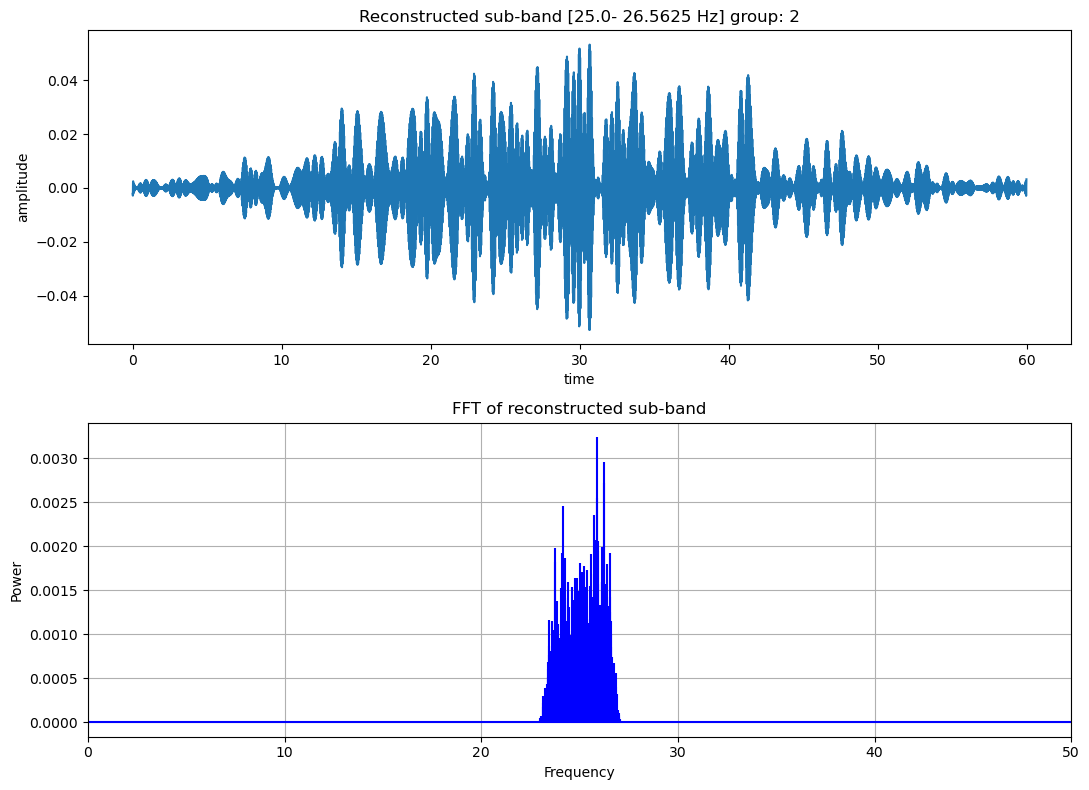

energy      0.003716
kurtosis    6.129198
crest       1.569638
entropy     0.093127
skewness   -0.485294
Name: 16, dtype: object


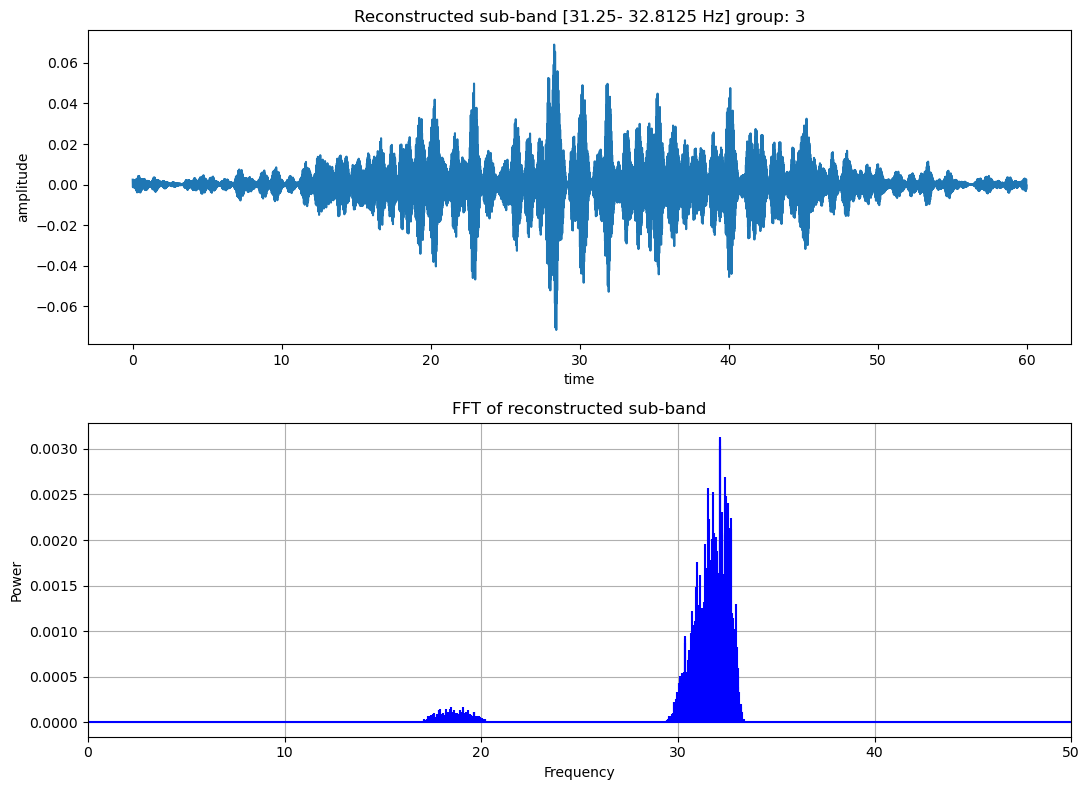

energy      0.003665
kurtosis    6.039678
crest       2.127211
entropy     0.092152
skewness    0.564485
Name: 20, dtype: object


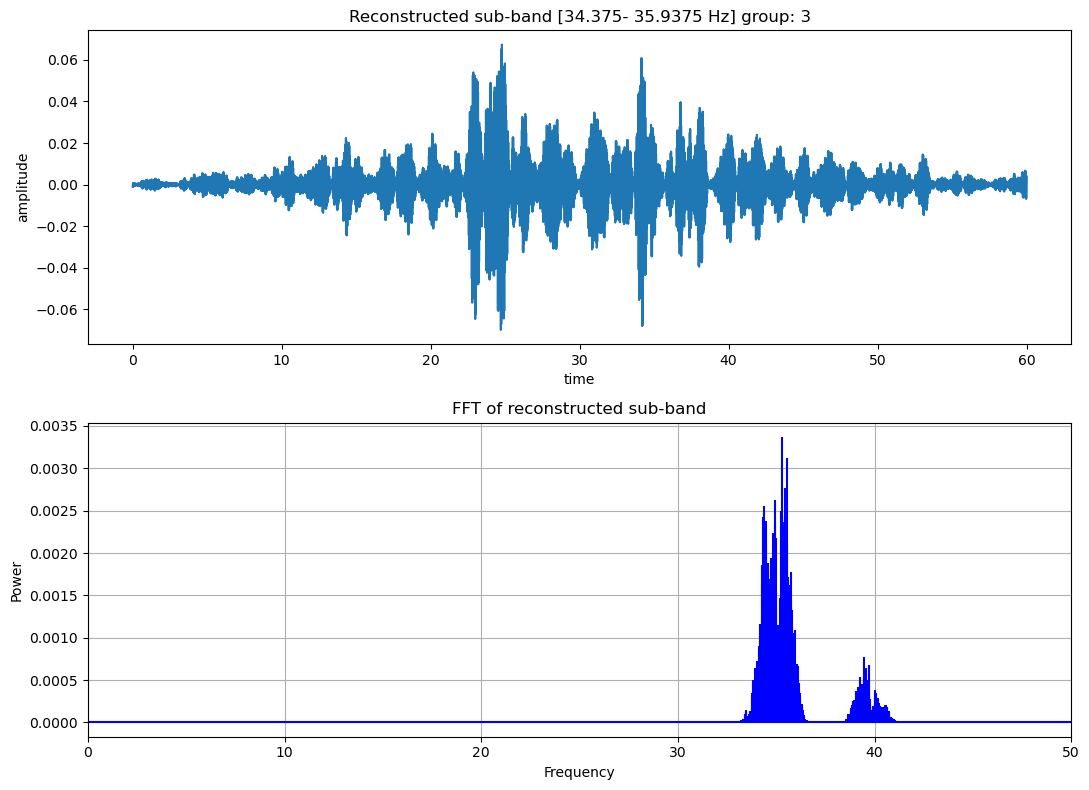

energy       0.003441
kurtosis    11.733936
crest        4.201365
entropy      0.087823
skewness    -1.842306
Name: 22, dtype: object


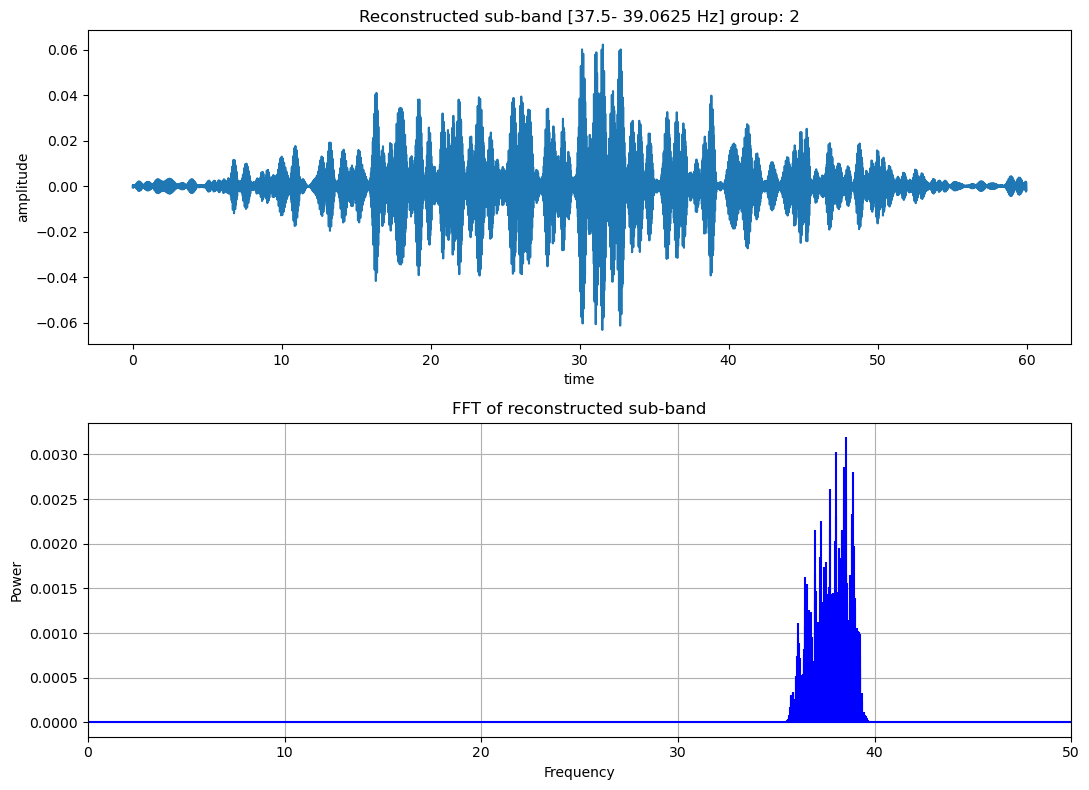

energy      0.003591
kurtosis    6.371665
crest       1.403599
entropy     0.090729
skewness   -0.053253
Name: 24, dtype: object


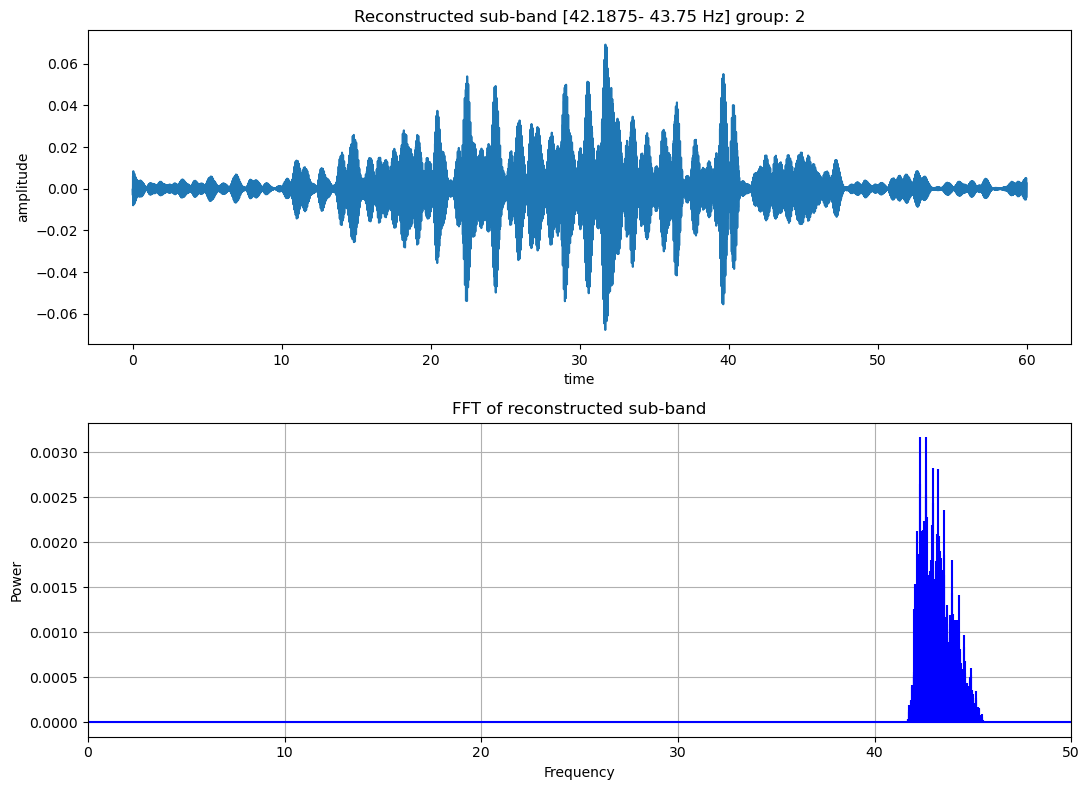

energy      0.003923
kurtosis    8.790892
crest       2.778718
entropy     0.097028
skewness    0.885938
Name: 27, dtype: object


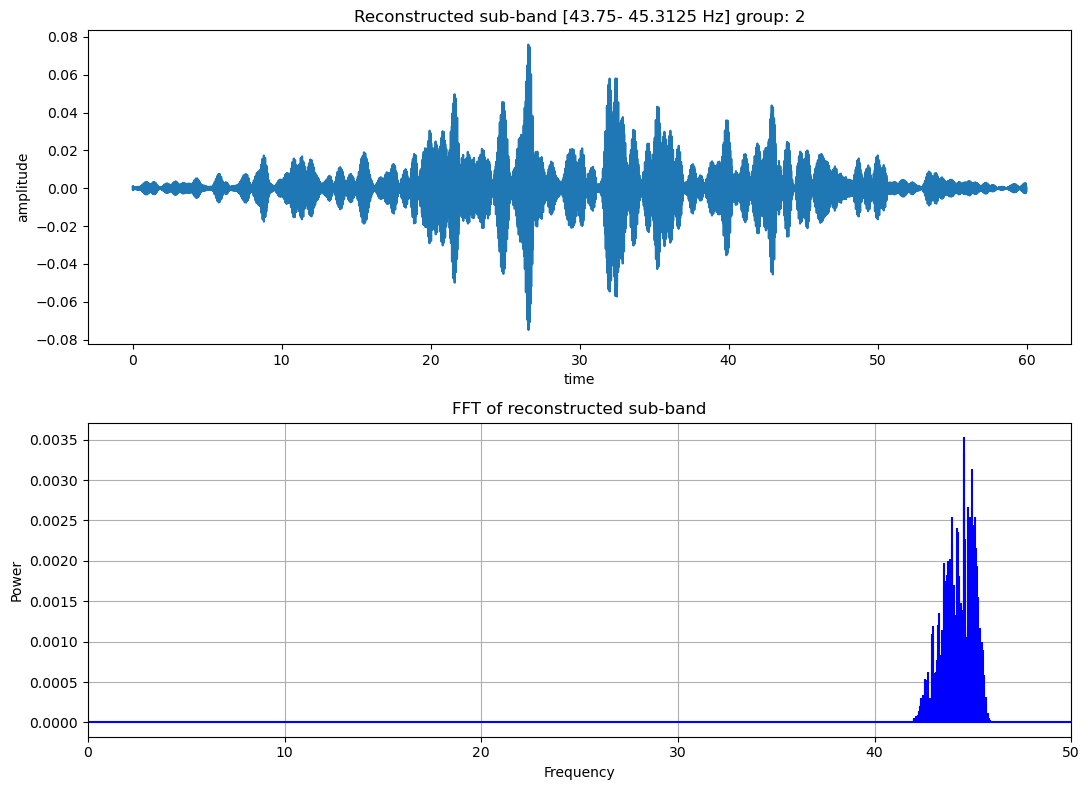

energy       0.003673
kurtosis    10.993478
crest        3.263172
entropy      0.092302
skewness    -0.580009
Name: 28, dtype: object


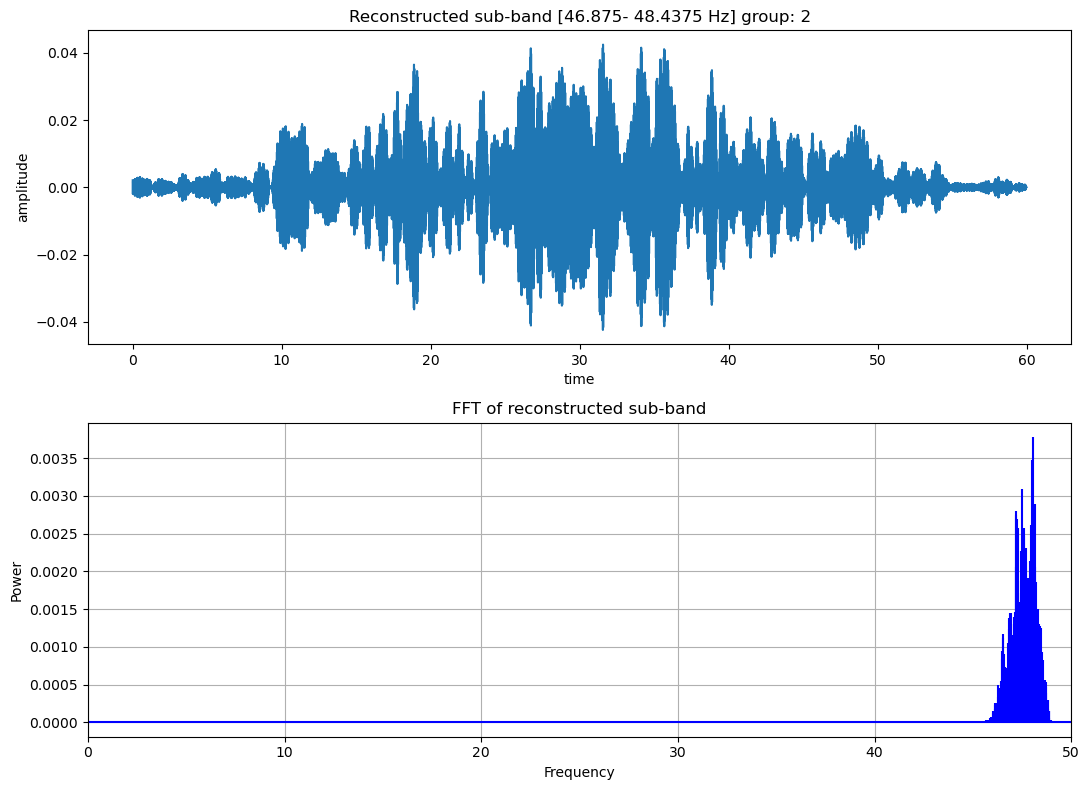

energy      0.003577
kurtosis    6.076148
crest       0.717207
entropy     0.090462
skewness    0.052969
Name: 30, dtype: object


In [275]:
plot_reconstructions(transient_data, group=reassigned_labels)

In [276]:
harmonics_data["node"].values.tolist()[0].frequency_range

(12.5, 14.0625)

<Axes: >

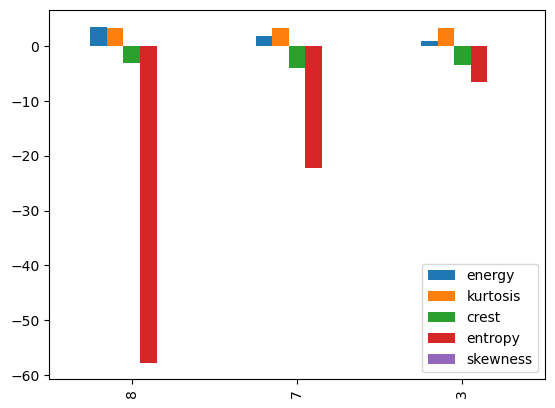

In [277]:
harmonics_data.plot.bar()

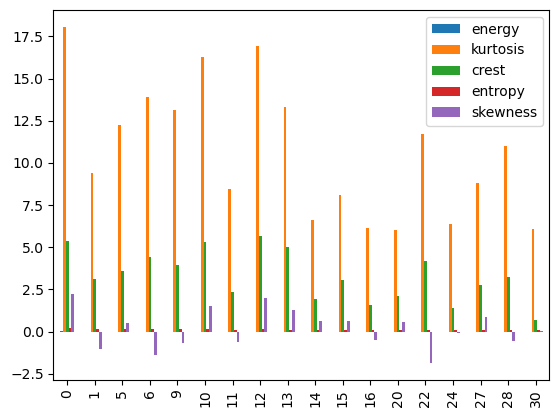

In [278]:
transient_data.plot.bar()
plt.show()